In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../../ecommerce_dataset_updated.csv")
df = df.rename(columns={"Price (Rs.)": "Price",
                        "Discount (%)": "Discount",
                        "Final_Price(Rs.)": "Final_Price"})
sns.set_theme(style="whitegrid")

top_cat = df["Category"].value_counts().idxmax()
top_pay = df["Payment_Method"].value_counts().idxmax()

## scatter plot

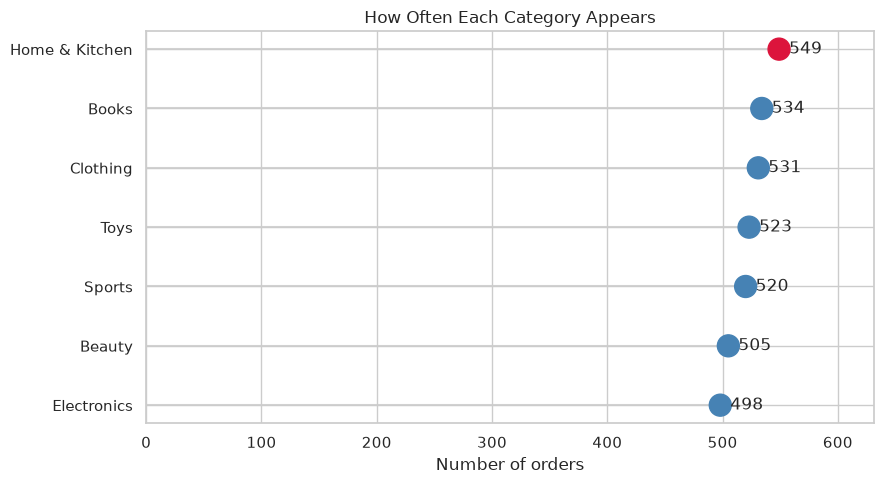

Most frequent Category: Home & Kitchen (549 orders, 15.0% of all orders)


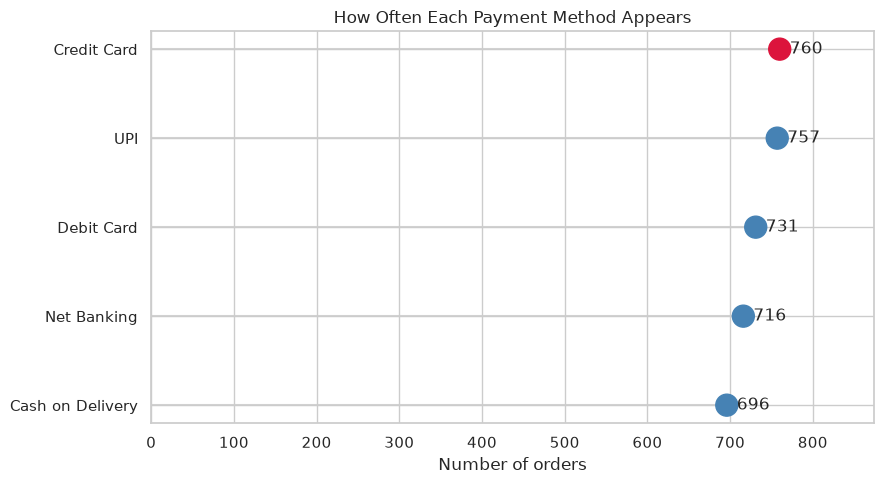

Most frequent Payment_Method: Credit Card (760 orders, 20.8% of all orders)


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../../ecommerce_dataset_updated.csv")

def count_plot(col, title):
    counts = df[col].value_counts().sort_values()          # smallest -> largest, so the biggest ends up on top
    colors = ["crimson" if v == counts.max() else "steelblue" for v in counts]

    plt.figure(figsize=(9, 5))
    plt.scatter(counts.values, counts.index, s=250, c=colors)
    plt.hlines(counts.index, 0, counts.values, color="lightgray", zorder=0)   # line from 0 to each dot
    for val, name in zip(counts.values, counts.index):
        plt.text(val, name, f"  {val}", va="center")
    plt.xlabel("Number of orders"); plt.title(title)
    plt.xlim(0, counts.max() * 1.15)
    plt.tight_layout(); plt.show()

    print(f"Most frequent {col}: {counts.idxmax()} ({counts.max()} orders, "
          f"{counts.max() / counts.sum():.1%} of all orders)")

count_plot("Category", "How Often Each Category Appears")
count_plot("Payment_Method", "How Often Each Payment Method Appears")

## pair plot

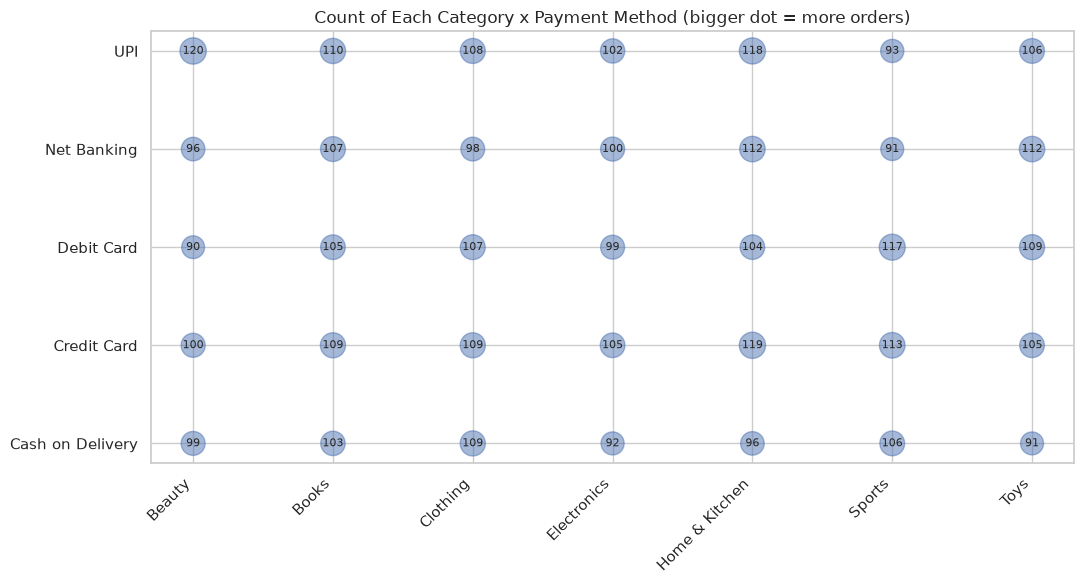

In [6]:
combo = df.groupby(["Category", "Payment_Method"]).size().reset_index(name="orders")

plt.figure(figsize=(11, 6))
plt.scatter(combo["Category"], combo["Payment_Method"], s=combo["orders"] * 3, alpha=0.5)
for _, r in combo.iterrows():
    plt.text(r["Category"], r["Payment_Method"], r["orders"], ha="center", va="center", fontsize=8)
plt.xticks(rotation=45, ha="right")
plt.title("Count of Each Category x Payment Method (bigger dot = more orders)")
plt.tight_layout(); plt.show()